# FT-Transformer — Employee Resignation Prediction

**Member 1 model:** FT-Transformer  
**Task:** Binary classification  
**Target:** `Resigned` (`1` = resigned)  
**Primary metric:** Average Precision / PR-AUC

## Objective

Evaluate FT-Transformer on the project's **80,000-row development partition** using the frozen **5-fold cross-validation** registry and all **17 approved predictors**.

The **20,000-row formal holdout remains locked**. It is excluded from preprocessing, class-weight calculation, inner validation, early stopping, hyperparameter screening, model selection, threshold analysis, and OOF evaluation.

**Final development status:** weighted FT-Transformer with leakage-safe inner validation, PR-AUC early stopping, controlled hyperparameter screening, and complete 80,000-row OOF evaluation.


## Individual variation evidence

The full five-fold weighted OOF result remains the group input. The table below is a **short exploratory input check**: the same 5,000 development training rows and 2,000 held-out rows from outer fold 1, five epochs, with salary kept or replaced by the **training-only median**. FT01/FT02 share their architecture and learning rate; FT02 uses fold-local positive-class weighting. Outer scores did not select the group configuration.

| Input preparation | FT01 AP, unweighted | FT02 AP, weighted |
|---|---:|---:|
| All 17 predictors | 0.101889 | 0.102254 |
| Salary masked at training median | 0.096129 | 0.101808 |

Neither input change establishes a reliable gain on this small sample. The full metric/validation table and other members' results are in [Individual model evidence](../../../../reports/INDIVIDUAL_MODEL_EVIDENCE.md). The reproducible check is `scripts/run_preprocessing_sensitivity.py`; it does not overwrite this notebook's historical weighted OOF files.


## Methodology and Leakage Controls

Each outer CV round uses **64,000 outer-training rows** and **16,000 untouched outer-validation rows**.

Inside each outer-training partition, the final adapter creates a stratified **15% inner-validation split**. The training pipeline then:

- fits `StandardScaler` only on inner-training numerical/ordinal predictors;
- learns categorical mappings only from inner-training data;
- reserves categorical index `0` for unknown/missing values;
- calculates positive-class weight from the inner-training target only;
- trains with `BCEWithLogitsLoss(pos_weight=...)`;
- monitors inner-validation **PR-AUC**;
- uses `ReduceLROnPlateau`;
- stops after 15 epochs without sufficient PR-AUC improvement, up to 100 epochs;
- restores the weights from the best inner-validation PR-AUC epoch.

A fresh adapter is created for each outer fold. `Employee_ID`, `Hire_Date`, and `Resigned` are never predictors. The shared OOF runner also rejects formal-holdout IDs.


In [1]:
# -----------------------------
# 1. Imports and project setup
# -----------------------------

import json
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import yaml
from IPython.display import display
from sklearn.metrics import precision_recall_curve

# Resolve the repository root from notebooks/team_contributions/models/member_1_ft_transformer/.
def find_project_root(start_path: Path | None = None) -> Path:
    """Locate the repository root from any notebook launch directory."""
    start = (start_path or Path.cwd()).resolve()
    for candidate in (start, *start.parents):
        if (candidate / "configs" / "feature_contract.yaml").is_file():
            return candidate
    raise FileNotFoundError("Could not locate repository root containing configs/feature_contract.yaml")

PROJECT_ROOT = find_project_root()

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.evaluation.metrics import calculate_binary_metrics
from src.models.ft_transformer import FTTransformerAdapter
from src.models.runner import run_5fold_cv

pd.set_option("display.max_columns", None)

CONFIG_PATH = PROJECT_ROOT / "configs" / "models" / "ft_transformer.yaml"
FEATURE_CONTRACT_PATH = PROJECT_ROOT / "configs" / "feature_contract.yaml"
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "Extended_Employee_Performance_and_Productivity_Data.csv"
SPLIT_PATH = PROJECT_ROOT / "data" / "processed" / "split_registry.csv"
RESULTS_DIR = PROJECT_ROOT / "results" / "models" / "ft_transformer"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

required_paths = [CONFIG_PATH, FEATURE_CONTRACT_PATH, DATA_PATH, SPLIT_PATH]
missing_paths = [str(path) for path in required_paths if not path.exists()]
assert not missing_paths, f"Missing required project files: {missing_paths}"

print("Project root:", PROJECT_ROOT)
print("Results directory:", RESULTS_DIR)


Project root: D:\Employee_Resignation_Prediction
Results directory: D:\Employee_Resignation_Prediction\results\models\ft_transformer


In [2]:
# 2. Load canonical configuration and define the retained historical run parameters
with open(CONFIG_PATH, "r", encoding="utf-8") as file:
    ft_config = yaml.safe_load(file)
with open(FEATURE_CONTRACT_PATH, "r", encoding="utf-8") as file:
    feature_contract = yaml.safe_load(file)

model_name = ft_config["model"]["name"]
model_id = ft_config["model"]["model_id"]
fixed_params = ft_config["fixed_params"].copy()
# The current config uses an explicit candidate registry rather than a legacy search_space block.
# FT02 has the historical architecture AND the required dynamic class weighting.
ft02 = next(c for c in ft_config["candidates"] if c["id"] == "FT02")
final_run_params = {**fixed_params, **ft02["params"], "validation_fraction_inner": ft_config["inner_validation"]["fraction"], "max_epochs": ft_config["inner_validation"]["max_epochs"], "patience": ft_config["inner_validation"]["patience"], "seed": ft_config["reproducibility"]["seed"]}
assert final_run_params["weighting"] == "dynamic_ratio"
historical_config = json.loads((RESULTS_DIR / "weighted_early_stopping_final" / "ft_transformer_final_configuration.json").read_text(encoding="utf-8"))
assert all(final_run_params[key] == value for key, value in historical_config.items()), "FT02 diverges from the recorded historical architecture"
config_summary = pd.DataFrame([(k,v) for k,v in final_run_params.items()], columns=["Setting","Value"])
display(config_summary)
print("Canonical candidate registry:", [c["id"] for c in ft_config["candidates"]])

,Setting,Value
0,optimizer,AdamW
1,weighting,dynamic_ratio
2,weight_decay,0.00001
3,attention_dropout,0.1
4,residual_dropout,0.0
5,batch_size,512
6,seed,42
7,max_epochs,100
8,patience,15
9,lr_scheduler,ReduceLROnPlateau


Canonical candidate registry: ['FT01', 'FT02', 'FT03', 'FT04', 'FT05', 'FT06', 'FT07', 'FT08']


In [3]:
# -----------------------------
# 3. Reproducibility and compute environment
# -----------------------------

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device_label = (
    torch.cuda.get_device_name(0)
    if torch.cuda.is_available()
    else "CPU"
)

print("Python kernel:", sys.executable)
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("Training device:", device_label)

if torch.cuda.is_available():
    print("PyTorch CUDA runtime:", torch.version.cuda)
    print(
        "GPU memory:",
        f"{torch.cuda.get_device_properties(0).total_memory / 1024**3:.2f} GB",
    )

print("Random seed:", fixed_params["seed"])


Python kernel: c:\Python314\python.exe
PyTorch version: 2.13.0+cpu
CUDA available: False
Training device: CPU
Random seed: 42


In [4]:
# -----------------------------
# 4. Load raw data and frozen split registry
# -----------------------------

df = pd.read_csv(DATA_PATH)
split_registry = pd.read_csv(SPLIT_PATH)

assert df.shape == (100_000, 20), f"Unexpected raw dataset shape: {df.shape}"
assert split_registry.shape == (100_000, 3), (
    f"Unexpected split-registry shape: {split_registry.shape}"
)
assert df["Employee_ID"].is_unique
assert split_registry["Employee_ID"].is_unique

print("Raw dataset shape:", df.shape)
print("Split registry shape:", split_registry.shape)
print("\nPartition counts:")
print(split_registry["partition"].value_counts())


Raw dataset shape: (100000, 20)
Split registry shape: (100000, 3)

Partition counts:
partition
development    80000
holdout        20000
Name: count, dtype: int64


In [5]:
# -----------------------------
# 5. Isolate the development partition and enforce holdout protection
# -----------------------------

development_ids = set(
    split_registry.loc[
        split_registry["partition"] == "development",
        "Employee_ID",
    ]
)
holdout_ids = set(
    split_registry.loc[
        split_registry["partition"] == "holdout",
        "Employee_ID",
    ]
)

development_data = (
    df.loc[df["Employee_ID"].isin(development_ids)]
    .copy()
    .reset_index(drop=True)
)

development_df = development_data.merge(
    split_registry[["Employee_ID", "partition", "cv_fold"]],
    on="Employee_ID",
    how="left",
    validate="one_to_one",
)
development_df["cv_fold"] = development_df["cv_fold"].astype(int)

assert len(development_data) == 80_000
assert "cv_fold" not in development_data.columns
assert "partition" not in development_data.columns
assert len(holdout_ids) == 20_000
assert set(development_data["Employee_ID"]).isdisjoint(holdout_ids)
assert set(development_df["cv_fold"].unique()) == {1, 2, 3, 4, 5}
assert development_df["cv_fold"].value_counts().eq(16_000).all()

print("Development rows:", len(development_data))
print("Formal holdout rows excluded:", len(holdout_ids))
print("Holdout IDs present in modeling data: 0")
print("\nDevelopment fold counts:")
print(development_df["cv_fold"].value_counts().sort_index())


Development rows: 80000
Formal holdout rows excluded: 20000
Holdout IDs present in modeling data: 0

Development fold counts:
cv_fold
1    16000
2    16000
3    16000
4    16000
5    16000
Name: count, dtype: int64


In [6]:
# -----------------------------
# 6. Validate the feature contract and build X / y
# -----------------------------

numerical_features = feature_contract["numerical_features"]
categorical_features = feature_contract["categorical_features"]
primary_model_features = feature_contract["primary_model_features"]
target_config = feature_contract["target"]

numerical_feature_names = [item["name"] for item in numerical_features]
categorical_feature_names = [item["name"] for item in categorical_features]
target_column = target_config["column"]

assert len(numerical_feature_names) == 13
assert len(categorical_feature_names) == 4
assert len(primary_model_features) == 17
assert set(numerical_feature_names + categorical_feature_names) == set(primary_model_features)

required_columns = primary_model_features + [target_column, "Employee_ID", "cv_fold"]
missing_columns = [c for c in required_columns if c not in development_df.columns]
assert not missing_columns, f"Missing required columns: {missing_columns}"

X = development_df[primary_model_features].copy()
y = development_df[target_column].astype(int).copy()
employee_ids = development_df["Employee_ID"].copy()
cv_folds = development_df["cv_fold"].copy()

assert X.shape == (80_000, 17)
assert len(y) == 80_000
assert set(y.unique()) == {0, 1}
assert X.isna().sum().sum() == 0
assert "Employee_ID" not in X.columns
assert "Hire_Date" not in X.columns
assert target_column not in X.columns

print("Predictor matrix:", X.shape)
print("Numerical / ordinal predictors:", len(numerical_feature_names))
print("Categorical predictors:", len(categorical_feature_names))
print("Missing predictor values:", int(X.isna().sum().sum()))
print("Development resignation prevalence:", f"{y.mean():.4%}")


Predictor matrix: (80000, 17)
Numerical / ordinal predictors: 13
Categorical predictors: 4
Missing predictor values: 0
Development resignation prevalence: 10.0100%


In [7]:
# -----------------------------
# 7. Verify fold balance
# -----------------------------

fold_summary = (
    development_df
    .groupby("cv_fold")[target_column]
    .agg(
        total_rows="size",
        resigned_count="sum",
        resignation_rate="mean",
    )
    .reset_index()
)

fold_summary["not_resigned_count"] = (
    fold_summary["total_rows"] - fold_summary["resigned_count"]
)
fold_summary["resignation_rate_pct"] = (
    fold_summary["resignation_rate"] * 100
).round(3)

fold_summary = fold_summary[
    [
        "cv_fold",
        "total_rows",
        "not_resigned_count",
        "resigned_count",
        "resignation_rate_pct",
    ]
]

assert len(fold_summary) == 5
assert (fold_summary["total_rows"] == 16_000).all()
assert (fold_summary["resigned_count"] > 0).all()
assert (fold_summary["not_resigned_count"] > 0).all()

display(fold_summary)


,cv_fold,total_rows,not_resigned_count,resigned_count,resignation_rate_pct
0,1,16000,14399,1601,10.006
1,2,16000,14399,1601,10.006
2,3,16000,14398,1602,10.013
3,4,16000,14398,1602,10.013
4,5,16000,14398,1602,10.013


In [8]:
# -----------------------------
# 8. Verify categorical coverage across outer folds
# -----------------------------

coverage_records = []

for fold in sorted(development_df["cv_fold"].unique()):
    train_fold_df = development_df[development_df["cv_fold"] != fold]
    val_fold_df = development_df[development_df["cv_fold"] == fold]

    for feature in categorical_feature_names:
        train_categories = set(train_fold_df[feature].dropna().unique())
        validation_categories = set(val_fold_df[feature].dropna().unique())
        unseen = validation_categories - train_categories

        coverage_records.append(
            {
                "cv_fold": fold,
                "feature": feature,
                "train_categories": len(train_categories),
                "validation_categories": len(validation_categories),
                "unseen_categories": len(unseen),
            }
        )

categorical_coverage = pd.DataFrame(coverage_records)
total_unseen = int(categorical_coverage["unseen_categories"].sum())

assert total_unseen == 0, (
    "At least one outer-validation fold contains a category absent "
    "from its corresponding training folds."
)

display(categorical_coverage)
print("\nTotal unseen validation categories:", total_unseen)


,cv_fold,feature,train_categories,validation_categories,unseen_categories
0,1,Department,9,9,0
1,1,Gender,3,3,0
2,1,Job_Title,7,7,0
3,1,Education_Level,4,4,0
4,2,Department,9,9,0
5,2,Gender,3,3,0
6,2,Job_Title,7,7,0
7,2,Education_Level,4,4,0
8,3,Department,9,9,0
9,3,Gender,3,3,0



Total unseen validation categories: 0


## Development History, Class Weighting, and Threshold Findings

Three main FT-Transformer development experiments were completed.

| Experiment | PR-AUC | ROC-AUC | F1 @ 0.50 | Brier | Main observation |
|---|---:|---:|---:|---:|---|
| Unweighted fixed baseline | 10.11% | 49.88% | 0.00% | 0.0907 | The default threshold produced effectively no positive predictions; ranking remained no-skill. |
| Weighted fixed baseline | 9.88% | 49.57% | 16.64% | 0.2515 | Weighting increased sensitivity to resignation, but did not improve ranking. |
| Weighted + early-stopping final | **10.00%** | **49.73%** | **16.73%** | **0.2474** | More controlled training, but discrimination remained approximately no-skill. |

Development resignation prevalence is approximately **10.01%**, so PR-AUC near 10% is approximately the no-skill reference.

### Why class weighting was introduced

The unweighted baseline produced an F1 of zero at threshold 0.50. To address class imbalance, the adapter was updated to calculate:

`pos_weight = negative_count / positive_count`

from the training data available inside the fold. In the final adapter, this is calculated from the **inner-training target only**.

### Threshold analysis

Threshold analysis on the **weighted fixed baseline OOF predictions** found a numerically highest F1 near threshold `0.05`, but that operating point predicted **every development employee as positive**:

- Precision ≈ 10.01%
- Recall = 100%
- F1 ≈ 18.20%
- Balanced accuracy = 50%
- Predicted-positive rate = 100%

That was a trivial all-positive classifier, so threshold adjustment was not adopted as a solution.


## Controlled Hyperparameter Screening

Hyperparameter screening used only the outer Fold 1 **training partition** and its internal validation split. The untouched Fold 1 outer-validation data was not used to choose hyperparameters.

Where a single-seed result suggested a potentially meaningful change, the strongest candidates were checked across seeds `42`, `123`, and `2026`.

| Parameter | Candidates examined | Retained value | Selection evidence |
|---|---|---:|---|
| Learning rate | 0.0001, 0.0003, 0.001 | **0.001** | Best multi-seed mean inner PR-AUC: 10.66% |
| `d_block` | 32, 64, 128 | **64** | Highest seed-42 inner PR-AUC: 10.76% |
| `n_blocks` | 2, 3, 4 | **3** | Best multi-seed mean inner PR-AUC: 10.66% |
| `ffn_d_hidden` | 64, 128, 256 | **128** | Best multi-seed mean inner PR-AUC: 10.66% |
| Attention heads | 2, 4, 8 | **4** | Highest seed-42 inner PR-AUC: 10.76% |
| FFN dropout | 0.0, 0.1, 0.2 | **0.1** | Highest seed-42 inner PR-AUC: 10.76% |

The apparent single-seed advantages from two Transformer blocks and FFN hidden size 64 did not remain superior across multiple seeds. The controlled search therefore returned to the original architecture.

Further FT-Transformer tuning was stopped to avoid overfitting the development process to validation noise.


## Final Verified FT-Transformer Execution Protocol

The final adapter implementation matches the intended development protocol:

1. The shared runner passes only the **outer-training rows** to `FTTransformerAdapter.fit()`.
2. The adapter creates a stratified **15% inner-validation split**.
3. Preprocessing and positive-class weighting are fitted/calculated from **inner-training data only**.
4. Training uses AdamW and weighted `BCEWithLogitsLoss`.
5. Inner-validation **PR-AUC** is evaluated after each epoch.
6. `ReduceLROnPlateau` monitors PR-AUC.
7. Early stopping uses patience 15 with a maximum of 100 epochs.
8. The best inner-validation PR-AUC weights are restored.
9. The shared runner predicts the untouched outer-validation fold.
10. The formal holdout remains unused.

The adapter also passes `ffn_d_hidden_multiplier=None` for compatibility with `rtdl_revisiting_models==0.0.2`.


In [9]:
# -----------------------------
# 9. Create a fresh final adapter factory
# -----------------------------

def make_final_ft_transformer():
    # Return a new unfitted adapter for each outer CV fold.
    return FTTransformerAdapter(
        name=model_name,
        model_id=model_id,
        params=final_run_params.copy(),
        categorical_features=categorical_feature_names.copy(),
    )

adapter_a = make_final_ft_transformer()
adapter_b = make_final_ft_transformer()

assert adapter_a is not adapter_b
assert adapter_a.params is not adapter_b.params
assert adapter_a.categorical_features is not adapter_b.categorical_features
assert adapter_a.params["weighting"] == "dynamic_ratio"
assert not adapter_a.get_metadata()["fitted"]
assert not adapter_b.get_metadata()["fitted"]

print("Final adapter factory validation passed.")
print("Model:", adapter_a.name)


Final adapter factory validation passed.
Model: FT-Transformer


In [10]:
# -----------------------------
# 10. Final weighted + early-stopping 5-fold OOF experiment
# -----------------------------

print("Final weighted + early-stopping FT-Transformer CV")
print("-------------------------------------------------")
print("Development rows:", len(development_data))
print("Formal holdout rows used: 0")
print("Predictors:", len(primary_model_features))
print("Outer folds: 5")
print("Maximum epochs:", final_run_params["max_epochs"])
print("Early-stopping patience:", final_run_params["patience"])
print(
    "Inner validation fraction:",
    final_run_params["validation_fraction_inner"],
)
print("Primary early-stopping metric: PR-AUC")
print("Class weighting: inner-training positive-class weight")
print("Device:", device_label)

# Ordinary Restart/Run All verifies the saved experiment without retraining or rewriting it.
# Deliberate retraining writes to a NEW, unique run directory; historical files are immutable.
RUN_FT_TRAINING = False
from datetime import datetime, timezone
from src.models.base import OOFResult
from src.evaluation.oof_validation import validate_oof_predictions

if RUN_FT_TRAINING:
    FINAL_ES_DIR = RESULTS_DIR / "reruns" / ("FT02_" + datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ"))
    FINAL_ES_DIR.mkdir(parents=True, exist_ok=False)
    final_cv_start = time.perf_counter()

    final_ft_cv_result = run_5fold_cv(
        adapter_factory=make_final_ft_transformer,

        # IMPORTANT:
        # Raw development rows only. The runner attaches split columns
        # from split_registry and protects the formal holdout.
        data=development_data,

        split_registry=split_registry,
        feature_cols=primary_model_features,
        target_col=target_column,
        id_col="Employee_ID",
        fold_col="cv_fold",
        partition_col="partition",
        development_label="development",
        holdout_label="holdout",
        expected_folds=(1, 2, 3, 4, 5),
        expected_model_name=model_name,
    )

    final_cv_elapsed = time.perf_counter() - final_cv_start

else:
    FINAL_ES_DIR = RESULTS_DIR / "weighted_early_stopping_final"
    predictions = pd.read_csv(FINAL_ES_DIR / "ft_transformer_final_oof_predictions.csv")
    recorded_folds = pd.read_csv(FINAL_ES_DIR / "ft_transformer_final_fold_metrics.csv")
    recorded_summary = json.loads((FINAL_ES_DIR / "ft_transformer_final_summary_metrics.json").read_text(encoding="utf-8"))
    recorded_metadata = json.loads((FINAL_ES_DIR / "ft_transformer_final_run_metadata.json").read_text(encoding="utf-8"))
    assert recorded_metadata["class_weighting"] == "inner-training positive-class weight"
    validate_oof_predictions(predictions, split_registry, source_data=df, expected_model_name=model_name)
    final_ft_cv_result = OOFResult(
        model_name=model_name, model_id=model_id, predictions=predictions,
        fold_metrics=recorded_folds, summary_metrics=recorded_summary,
        fit_time_seconds_total=float(recorded_summary["total_fit_time_seconds"]),
        predict_time_seconds_total=float(recorded_summary["total_predict_time_seconds"]),
        metadata=recorded_metadata,
    )
    final_cv_elapsed = float(recorded_metadata["elapsed_minutes"]) * 60
    print("Loaded and validated recorded weighted OOF evidence; training was skipped.")

assert len(final_ft_cv_result.predictions) == 80_000
assert final_ft_cv_result.predictions["Employee_ID"].is_unique
assert set(final_ft_cv_result.predictions["cv_fold"].unique()) == {1, 2, 3, 4, 5}
assert set(final_ft_cv_result.predictions["Employee_ID"]).isdisjoint(holdout_ids)

print("\nFT-Transformer development evidence ready.")
print("Elapsed time:", f"{final_cv_elapsed / 60:.2f} minutes")
print("OOF prediction rows:", len(final_ft_cv_result.predictions))


Final weighted + early-stopping FT-Transformer CV
-------------------------------------------------
Development rows: 80000
Formal holdout rows used: 0
Predictors: 17
Outer folds: 5
Maximum epochs: 100
Early-stopping patience: 15
Inner validation fraction: 0.15
Primary early-stopping metric: PR-AUC
Class weighting: inner-training positive-class weight
Device: CPU
Loaded and validated recorded weighted OOF evidence; training was skipped.

FT-Transformer development evidence ready.
Elapsed time: 6.20 minutes
OOF prediction rows: 80000


### Recorded Final Development Run

The completed final run used an **NVIDIA GeForce RTX 4060 Laptop GPU** and finished in approximately **6.20 minutes**.

| Metric | Recorded value |
|---|---:|
| Pooled PR-AUC / Average Precision | **0.099979** |
| Pooled ROC-AUC | **0.497254** |
| Pooled F1 @ 0.50 | **0.167258** |
| Pooled Brier score | **0.247413** |
| CV mean PR-AUC | **0.099696** |
| CV SD PR-AUC | **0.002237** |
| CV mean ROC-AUC | **0.497570** |
| CV SD ROC-AUC | **0.006597** |
| Total fit time | **370.72 s** |
| Total prediction time | **1.19 s** |

The run produced one OOF prediction for each of the **80,000 development employees** and used **zero formal-holdout rows**.


In [11]:
# -----------------------------
# 11. Fold-level and pooled OOF performance
# -----------------------------

fold_metrics = final_ft_cv_result.fold_metrics.copy()
oof_predictions = final_ft_cv_result.predictions.copy()

expected_metric_columns = {
    "fold",
    "average_precision",
    "roc_auc",
    "precision",
    "recall",
    "f1",
    "balanced_accuracy",
    "brier_score",
    "fit_time_seconds",
    "predict_time_seconds",
}

missing_metric_columns = expected_metric_columns - set(fold_metrics.columns)
assert not missing_metric_columns, (
    f"Fold metrics are missing columns: {sorted(missing_metric_columns)}"
)
assert len(fold_metrics) == 5

display(
    fold_metrics[
        [
            "fold",
            "average_precision",
            "roc_auc",
            "brier_score",
            "balanced_accuracy",
            "precision",
            "recall",
            "f1",
            "predicted_positive_rate",
            "fit_time_seconds",
            "predict_time_seconds",
        ]
    ].round(6)
)

pooled_metrics = calculate_binary_metrics(
    y_true=oof_predictions["y_true"],
    y_probability=oof_predictions["y_probability"],
    y_pred=oof_predictions["y_pred_0_5"],
    threshold=0.50,
)

prevalence = float(oof_predictions["y_true"].mean())
no_skill_ap = prevalence
constant_prevalence_brier = prevalence * (1.0 - prevalence)

metric_summary = pd.DataFrame(
    [
        ("Average Precision / PR-AUC", pooled_metrics["average_precision"]),
        ("No-skill AP (prevalence)", no_skill_ap),
        ("ROC-AUC", pooled_metrics["roc_auc"]),
        ("Brier score", pooled_metrics["brier_score"]),
        ("Constant-prevalence Brier reference", constant_prevalence_brier),
        ("Balanced accuracy @ 0.50", pooled_metrics["balanced_accuracy"]),
        ("Precision @ 0.50", pooled_metrics["precision"]),
        ("Recall @ 0.50", pooled_metrics["recall"]),
        ("F1 @ 0.50", pooled_metrics["f1"]),
        (
            "Predicted-positive rate @ 0.50",
            pooled_metrics["predicted_positive_rate"],
        ),
    ],
    columns=["Metric", "Value"],
)

print("\nPooled OOF metrics")
display(metric_summary.round(6))

print(
    "PR-AUC lift over prevalence:",
    f"{pooled_metrics['average_precision'] - no_skill_ap:+.6f}",
)


,fold,average_precision,roc_auc,brier_score,balanced_accuracy,precision,recall,f1,predicted_positive_rate,fit_time_seconds,predict_time_seconds
0,1,0.096579,0.485936,0.242199,0.491374,0.095721,0.342286,0.149604,0.357812,93.375514,0.223572
1,2,0.102827,0.501306,0.255291,0.502728,0.100974,0.544035,0.170333,0.539125,156.767362,0.214821
2,3,0.100136,0.500504,0.217159,0.500000,0.000000,0.000000,0.000000,0.000000,44.011174,0.244908
3,4,0.099155,0.498664,0.261640,0.498523,0.099760,0.726592,0.175433,0.729250,44.829481,0.267360
4,5,0.099781,0.501442,0.260776,0.501856,0.100468,0.978152,0.182220,0.974812,31.731506,0.244332



Pooled OOF metrics


,Metric,Value
0,Average Precision / PR-AUC,0.099979
1,No-skill AP (prevalence),0.100100
2,ROC-AUC,0.497254
3,Brier score,0.247413
4,Constant-prevalence Brier reference,0.090080
5,Balanced accuracy @ 0.50,0.498906
6,Precision @ 0.50,0.099721
7,Recall @ 0.50,0.518232
8,F1 @ 0.50,0.167258
9,Predicted-positive rate @ 0.50,0.520200


PR-AUC lift over prevalence: -0.000121


,Statistic,Probability
0,Minimum,0.159644
1,1st percentile,0.332647
2,25th percentile,0.464220
3,Median,0.502251
4,Mean,0.493553
5,75th percentile,0.518548
6,99th percentile,0.627385
7,Maximum,0.791558


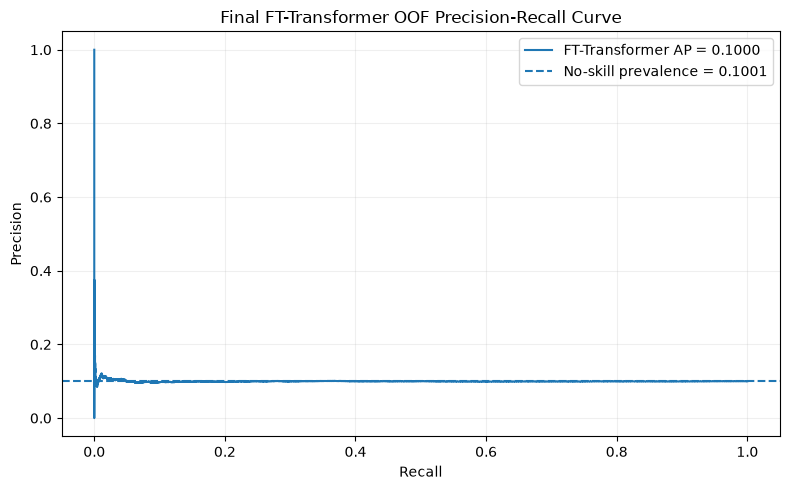

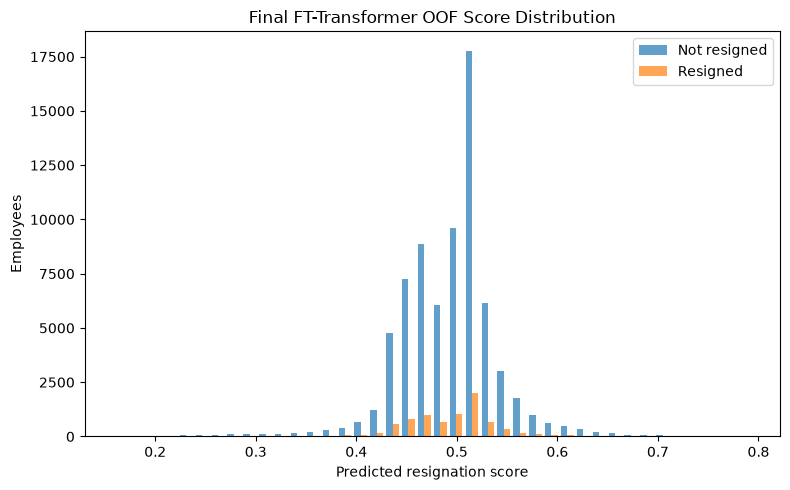

In [12]:
# -----------------------------
# 12. Final probability diagnostics and figures
# -----------------------------

probabilities = oof_predictions["y_probability"]

probability_summary = pd.DataFrame(
    {
        "Statistic": [
            "Minimum",
            "1st percentile",
            "25th percentile",
            "Median",
            "Mean",
            "75th percentile",
            "99th percentile",
            "Maximum",
        ],
        "Probability": [
            probabilities.min(),
            probabilities.quantile(0.01),
            probabilities.quantile(0.25),
            probabilities.median(),
            probabilities.mean(),
            probabilities.quantile(0.75),
            probabilities.quantile(0.99),
            probabilities.max(),
        ],
    }
)

display(probability_summary.round(6))

# FINAL_ES_DIR was selected in the evaluation cell: historical read-only or new rerun.

precision, recall, _ = precision_recall_curve(
    oof_predictions["y_true"],
    oof_predictions["y_probability"],
)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(
    recall,
    precision,
    label=f"FT-Transformer AP = {pooled_metrics['average_precision']:.4f}",
)
ax.axhline(
    prevalence,
    linestyle="--",
    label=f"No-skill prevalence = {prevalence:.4f}",
)
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Final FT-Transformer OOF Precision-Recall Curve")
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()

pr_curve_path = (
    FINAL_ES_DIR / "figure_01_final_ft_transformer_precision_recall_curve.png"
)
if RUN_FT_TRAINING:
    fig.savefig(pr_curve_path, dpi=150, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(
    [
        oof_predictions.loc[
            oof_predictions["y_true"] == 0,
            "y_probability",
        ],
        oof_predictions.loc[
            oof_predictions["y_true"] == 1,
            "y_probability",
        ],
    ],
    bins=40,
    label=["Not resigned", "Resigned"],
    alpha=0.7,
)
ax.set_xlabel("Predicted resignation score")
ax.set_ylabel("Employees")
ax.set_title("Final FT-Transformer OOF Score Distribution")
ax.legend()
fig.tight_layout()

probability_plot_path = (
    FINAL_ES_DIR / "figure_02_final_ft_transformer_oof_score_distribution.png"
)
if RUN_FT_TRAINING:
    fig.savefig(probability_plot_path, dpi=150, bbox_inches="tight")
plt.show()


In [13]:
# -----------------------------
# 13. Save final weighted + early-stopping artifacts
# -----------------------------

# Historical files are read-only; deliberate reruns use the new directory above.

oof_path = FINAL_ES_DIR / "ft_transformer_final_oof_predictions.csv"
fold_metrics_path = FINAL_ES_DIR / "ft_transformer_final_fold_metrics.csv"
summary_path = FINAL_ES_DIR / "ft_transformer_final_summary_metrics.json"
config_path = FINAL_ES_DIR / "ft_transformer_final_configuration.json"
metadata_path = FINAL_ES_DIR / "ft_transformer_final_run_metadata.json"

if RUN_FT_TRAINING:
    oof_predictions.to_csv(oof_path, index=False)
    fold_metrics.to_csv(fold_metrics_path, index=False)

    with open(summary_path, "w", encoding="utf-8") as file:
        json.dump(final_ft_cv_result.summary_metrics, file, indent=4, default=float)

    with open(config_path, "w", encoding="utf-8") as file:
        json.dump(final_run_params, file, indent=4, default=float)

    run_metadata = {
        "model": model_name,
        "model_id": model_id,
        "experiment": "FT02_weighted_rerun",
        "feature_count": len(primary_model_features),
        "features": primary_model_features,
        "categorical_features": categorical_feature_names,
        "numerical_features": numerical_feature_names,
        "development_rows": len(development_data),
        "formal_holdout_rows_used": 0,
        "outer_cv_folds": [1, 2, 3, 4, 5],
        "class_weighting": "inner-training positive-class weight",
        "candidate_id": "FT02",
        "pos_weight_formula": "negative_count / positive_count",
        "inner_validation_fraction": final_run_params["validation_fraction_inner"],
        "early_stopping_metric": "PR-AUC",
        "maximum_epochs": final_run_params["max_epochs"],
        "patience": final_run_params["patience"],
        "learning_rate_scheduler": "ReduceLROnPlateau",
        "best_weights_restored": True,
        "batch_size": 512,
        "device": device_label,
        "torch_version": torch.__version__,
        "torch_cuda_runtime": torch.version.cuda,
        "cuda_available": bool(torch.cuda.is_available()),
        "executed_params": final_run_params,
        "pooled_pr_auc": final_ft_cv_result.summary_metrics[
            "pooled_average_precision"
        ],
        "pooled_roc_auc": final_ft_cv_result.summary_metrics[
            "pooled_roc_auc"
        ],
        "elapsed_minutes": final_cv_elapsed / 60,
    }

    with open(metadata_path, "w", encoding="utf-8") as file:
        json.dump(run_metadata, file, indent=4, default=float)

else:
    print("Preserved historical artifacts; no result files rewritten.")

saved_files = [
    oof_path,
    fold_metrics_path,
    summary_path,
    config_path,
    metadata_path,
    pr_curve_path,
    probability_plot_path,
]

assert all(path.exists() for path in saved_files)

print("Final FT-Transformer artifacts saved:")
for path in saved_files:
    print(" ✓", path.name, f"({path.stat().st_size:,} bytes)")


Preserved historical artifacts; no result files rewritten.
Final FT-Transformer artifacts saved:
 ✓ ft_transformer_final_oof_predictions.csv (3,760,505 bytes)
 ✓ ft_transformer_final_fold_metrics.csv (1,204 bytes)
 ✓ ft_transformer_final_summary_metrics.json (709 bytes)
 ✓ ft_transformer_final_configuration.json (428 bytes)
 ✓ ft_transformer_final_run_metadata.json (2,482 bytes)
 ✓ figure_01_final_ft_transformer_precision_recall_curve.png (38,875 bytes)
 ✓ figure_02_final_ft_transformer_oof_score_distribution.png (36,757 bytes)


In [14]:
# -----------------------------
# 14. Review preserved tuning and baseline evidence
# -----------------------------

TUNING_DIR = FINAL_ES_DIR / "tuning"
tuning_summary_path = TUNING_DIR / "final_tuning_summary.csv"

if tuning_summary_path.exists():
    tuning_summary = pd.read_csv(tuning_summary_path)
    print("Preserved tuning summary:")
    display(tuning_summary)
else:
    print(
        "Tuning summary artifact is not present in this checkout. "
        "The recorded screening decisions are documented above."
    )

print("\nHistorical artifact directories:")
for directory_name in [
    "unweighted_baseline",
    "weighted_fixed_baseline",
    "weighted_early_stopping_final",
]:
    path = RESULTS_DIR / directory_name
    print(
        f" - {directory_name}:",
        "present" if path.exists() else "not present",
    )


Preserved tuning summary:


,parameter,tested,retained_value,selection_evidence
0,learning_rate,"0.0001, 0.0003, 0.001",0.001,Best multi-seed mean inner PR-AUC: 10.66%
1,d_block,"32, 64, 128",64.000,Highest seed-42 inner PR-AUC: 10.76%
2,n_blocks,"2, 3, 4",3.000,Best multi-seed mean inner PR-AUC: 10.66%
3,ffn_d_hidden,"64, 128, 256",128.000,Best multi-seed mean inner PR-AUC: 10.66%
4,attention_n_heads,"2, 4, 8",4.000,Highest seed-42 inner PR-AUC: 10.76%
5,ffn_dropout,"0.0, 0.1, 0.2",0.100,Highest seed-42 inner PR-AUC: 10.76%



Historical artifact directories:
 - unweighted_baseline: present
 - weighted_fixed_baseline: present
 - weighted_early_stopping_final: present


In [15]:
# -----------------------------
# 15. Final integrity and consistency checks
# -----------------------------

assert len(oof_predictions) == 80_000
assert oof_predictions["Employee_ID"].nunique() == 80_000
assert set(oof_predictions["Employee_ID"]).isdisjoint(holdout_ids)
assert oof_predictions["y_probability"].between(0, 1).all()
assert oof_predictions["y_probability"].notna().all()
assert set(oof_predictions["cv_fold"].unique()) == {1, 2, 3, 4, 5}

assert len(fold_metrics) == 5
assert set(fold_metrics["fold"]) == {1, 2, 3, 4, 5}

assert np.isclose(
    pooled_metrics["average_precision"],
    final_ft_cv_result.summary_metrics["pooled_average_precision"],
)
assert np.isclose(
    pooled_metrics["roc_auc"],
    final_ft_cv_result.summary_metrics["pooled_roc_auc"],
)
assert np.isclose(
    pooled_metrics["brier_score"],
    final_ft_cv_result.summary_metrics["pooled_brier_score"],
)

expected_final_params = {
    "learning_rate": 0.001,
    "d_block": 64,
    "n_blocks": 3,
    "ffn_d_hidden": 128,
    "attention_n_heads": 4,
    "ffn_dropout": 0.1,
    "attention_dropout": 0.1,
    "residual_dropout": 0.0,
    "max_epochs": 100,
    "patience": 15,
    "validation_fraction_inner": 0.15,
    "seed": 42,
    "weighting": "dynamic_ratio",
}

for key, expected_value in expected_final_params.items():
    assert final_run_params[key] == expected_value, (
        f"{key}: expected {expected_value}, "
        f"found {final_run_params[key]}"
    )

required_final_artifacts = [
    oof_path,
    fold_metrics_path,
    summary_path,
    config_path,
    metadata_path,
]
missing_artifacts = [
    str(path)
    for path in required_final_artifacts
    if not path.exists()
]
assert not missing_artifacts, f"Missing final artifacts: {missing_artifacts}"

print("All final FT-Transformer integrity checks passed.")
print("80,000 development OOF predictions verified.")
print("Formal holdout remains untouched.")
print("Final development result is ready for cross-model comparison.")


All final FT-Transformer integrity checks passed.
80,000 development OOF predictions verified.
Formal holdout remains untouched.
Final development result is ready for cross-model comparison.


## Final FT-Transformer Conclusion

FT-Transformer was evaluated on all **17 approved predictors** using the frozen five-fold development protocol. The formal **20,000-row holdout was never used**.

### Final weighted + early-stopping result

- **Pooled PR-AUC / Average Precision:** 0.099979
- **Pooled ROC-AUC:** 0.497254
- **Pooled F1 @ 0.50:** 0.167258
- **Pooled Brier score:** 0.247413

Development resignation prevalence is approximately **10.01%**. The final PR-AUC is therefore approximately equal to the no-skill prevalence reference, while ROC-AUC is approximately 0.50.

Class weighting changed threshold behavior and increased sensitivity to the minority class, but it did not improve ranking discrimination. The weighted scores were also poorly calibrated, so they should not be interpreted directly as real-world resignation probabilities without a later calibration stage.

The final fold-level threshold behavior was unstable: one outer fold produced no positive predictions at threshold 0.50, while another predicted almost all rows as positive. This reinforces the use of ranking metrics for model comparison rather than treating the raw weighted scores as calibrated probabilities.

Controlled learning-rate and architecture screening did not identify a consistently superior FT-Transformer configuration. Further tuning was stopped to avoid excessive optimization to development-only validation noise.

**Development conclusion:** FT-Transformer does not demonstrate meaningful resignation discrimination on the approved feature set under the tested protocol.

The **weighted + inner-validation early-stopping experiment** is retained as the principal FT-Transformer development result. The unweighted and weighted fixed runs remain preserved as historical baselines. The formal holdout remains locked for the later pipeline-frozen final evaluation stage.


## Current evidence status

The saved FT-Transformer OOF artefacts remain valid historical development evidence, but they were produced under the earlier controlled-screening workflow. The repository now contains a stricter eight-candidate nested-selection adapter/configuration. The current notebook verifies the retained weighted experiment through FT02 and loads its saved OOF evidence by default. A deliberate rerun uses a separate directory. The newer eight-candidate strict-nested FT search has not been executed, so the retained controlled-screening result remains clearly labeled as historical evidence. The formal holdout remains untouched.